# Predicción de captación de clientes — TP Final

**Aprendizaje Artificial** · Maestría en Gestión y Desarrollo de Inteligencia Artificial · Universidad CAECE
**Autor:** Fernando Caceres · **Docentes:** Juan Azcurra · Paul Pablo Hernán

<a href="https://colab.research.google.com/github/fcaceres-create/caece-aprendizaje-artificial-tpfinal/blob/main/notebooks/TP_final_colab.ipynb" target="_blank"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Abrir en Colab"></a>

Este notebook reproduce el trabajo de punta a punta en Google Colab, siguiendo CRISP-DM:

1. **Instalación** del código del repositorio y sus dependencias.
2. **Datos:** descarga del dataset *Bank Marketing* desde UCI y verificación byte a byte contra los archivos de la consigna.
3. **Preparación:** detección y eliminación del solapamiento entre train y test.
4. **Exploración** de los datos.
5. **Modelado:** modo rápido, que usa el modelo ya entrenado, o modo completo, que reentrena todo.
6. **Evaluación** única sobre el hold-out y análisis de negocio.
7. **Explicabilidad** con SHAP.
8. **Uso del modelo** y llamada a la API publicada.

**Enlaces**
- App web: https://captacion-clientes.onrender.com
- Presentación: https://fcaceres-create.github.io/caece-aprendizaje-artificial-tpfinal/presentacion/
- Código: https://github.com/fcaceres-create/caece-aprendizaje-artificial-tpfinal

> **Cómo ejecutarlo:** *Entorno de ejecución → Ejecutar todo*. La primera celda instala las librerías y
> **reinicia el entorno automáticamente** (es necesario para que tome las versiones correctas). Cuando
> termine el reinicio, volver a hacer *Ejecutar todo*: la segunda vez la instalación se saltea.

In [1]:
# 1. Instalación (en Colab clona el repo, instala versiones fijas y reinicia el entorno una sola vez)
import os, sys, subprocess
from pathlib import Path

EN_COLAB = "google.colab" in sys.modules
REPO_DIR = Path("/content/caece-aprendizaje-artificial-tpfinal") if EN_COLAB else Path.cwd().resolve().parent

if EN_COLAB:
    if not REPO_DIR.exists():
        subprocess.run(["git", "clone", "-q", "https://github.com/fcaceres-create/caece-aprendizaje-artificial-tpfinal.git", str(REPO_DIR)], check=True)
    marker = Path("/content/.tp_instalado")
    if not marker.exists():
        print("Instalando dependencias (2-3 minutos)...")
        subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                        "pandas==3.0.6", "numpy==2.5.3", "scikit-learn==1.9.1", "imbalanced-learn==0.14.2",
                        "lightgbm==4.7.0", "xgboost==3.4.1", "shap==0.52.0", "optuna==5.0.0",
                        "matplotlib==3.11.2", "seaborn==0.13.2", "joblib==1.6.0", "requests"], check=True)
        marker.touch()
        print("Listo. Reiniciando el entorno: cuando termine, volver a 'Ejecutar todo'.")
        os.kill(os.getpid(), 9)

os.chdir(REPO_DIR)
sys.path.insert(0, str(REPO_DIR / "src"))
import pandas as pd, numpy as np, sklearn, lightgbm
print("Repositorio:", REPO_DIR)
print("pandas", pd.__version__, "· numpy", np.__version__, "· scikit-learn", sklearn.__version__, "· lightgbm", lightgbm.__version__)

Repositorio: C:\Antigravity\CAECE\caece_aprendizaje_artificial_final
pandas 3.0.6 · numpy 2.5.3 · scikit-learn 1.9.1 · lightgbm 4.7.0


## 2. Datos: descarga desde UCI y verificación

Los archivos de la consigna (`banca_train.csv`, `banca_test.csv`) no se versionan en el repositorio. Son el
dataset público *Bank Marketing* (Moro, Cortez y Rita, 2014). Se descargan desde UCI y se comprueba con
SHA-256 que son **exactamente** los mismos archivos:

- `banca_train.csv` = `bank-full.csv`
- `banca_test.csv` = `bank.csv`

In [2]:
import hashlib, io, json, urllib.request, zipfile
from bank_captacion import config as cfg

URL = "https://archive.ics.uci.edu/static/public/222/bank+marketing.zip"
esperado = json.loads((cfg.TABLES_DIR / "data_info.json").read_text())   # hashes registrados en el proyecto
cfg.DATA_RAW.mkdir(parents=True, exist_ok=True)

if not (cfg.TRAIN_FILE.exists() and cfg.TEST_FILE.exists()):
    zbytes = urllib.request.urlopen(URL, timeout=120).read()
    interno = zipfile.ZipFile(io.BytesIO(zipfile.ZipFile(io.BytesIO(zbytes)).read("bank.zip")))
    cfg.TRAIN_FILE.write_bytes(interno.read("bank-full.csv"))
    cfg.TEST_FILE.write_bytes(interno.read("bank.csv"))

for nombre, ruta, clave in [("banca_train.csv", cfg.TRAIN_FILE, "train_sha256"), ("banca_test.csv", cfg.TEST_FILE, "test_sha256")]:
    h = hashlib.sha256(ruta.read_bytes()).hexdigest()
    print(f"{nombre:16s} {h[:16]}…  {'✓ idéntico al de la consigna' if h == esperado[clave] else '✗ DISTINTO'}")

banca_train.csv  d1513ec63b385506…  ✓ idéntico al de la consigna
banca_test.csv   dc8d576e9bda0f41…  ✓ idéntico al de la consigna


## 3. Preparación: el hallazgo crítico

Al comparar los dos archivos, **las 4.521 filas del test aparecen idénticas dentro del train**: `bank.csv`
es una muestra de `bank-full.csv`. Si no se corrige, la evaluación final mide memoria y no generalización.
Por eso se quitan esas filas del train, que queda en 40.690.

In [3]:
from IPython.display import Image, display
from bank_captacion.data import prepare_datasets

info = prepare_datasets()
display(pd.read_csv(cfg.TABLES_DIR / "data_summary.csv"))
display(pd.read_csv(cfg.TABLES_DIR / "data_preparation_steps.csv")[["order", "step", "dataset", "rows_before", "rows_after", "reason"]])
print("¿Partición aleatoria o temporal? (p > 0,05 = sin diferencias)")
display(pd.read_csv(cfg.TABLES_DIR / "split_checks.csv"))

,dataset,rows,cols,positives,positive_rate_pct,exact_duplicates,nulls,test_rows_found_in_train
0,train_raw,45211,17,5289,11.70,0,0,4521.0
1,train_clean,40690,17,4768,11.72,0,0,0.0
2,test,4521,17,521,11.52,0,0,NaN


,order,step,dataset,rows_before,rows_after,reason
0,1,load,train,45211,45211,banca_train.csv leído con sep=';' y encoding A...
1,2,load,test,4521,4521,banca_test.csv leído con sep=';' y encoding AS...
2,3,check_exact_duplicates,train,45211,45211,Duplicados exactos dentro de train: 0. No se e...
3,4,check_exact_duplicates,test,4521,4521,Duplicados exactos dentro de test: 0. No se el...
4,5,check_nulls,train+test,49732,49732,"Nulos: train=0, test=0. Los faltantes vienen c..."
5,6,remove_train_test_overlap,train,45211,40690,4521 de 4521 filas de test (100.0 %) aparecen ...
6,7,save_processed,train,40690,40690,Guardado en data/processed/train_clean.csv (si...
7,8,save_processed,test,4521,4521,Guardado en data/processed/test_clean.csv (idé...


¿Partición aleatoria o temporal? (p > 0,05 = sin diferencias)


,check,statistic,p_value,detail
0,posiciones_test_en_train_vs_uniforme (KS),0.0136,0.3715,"posición media relativa = 0.495 (0,5 si es uni..."
1,distribucion_month_train_vs_test (chi2),10.7070,0.4681,12 niveles
2,distribucion_contact_train_vs_test (chi2),1.2270,0.5414,3 niveles
3,distribucion_poutcome_train_vs_test (chi2),4.6370,0.2004,4 niveles
4,distribucion_y_train_vs_test (chi2),0.1300,0.7186,2 niveles


## 4. Exploración de los datos (solo train)

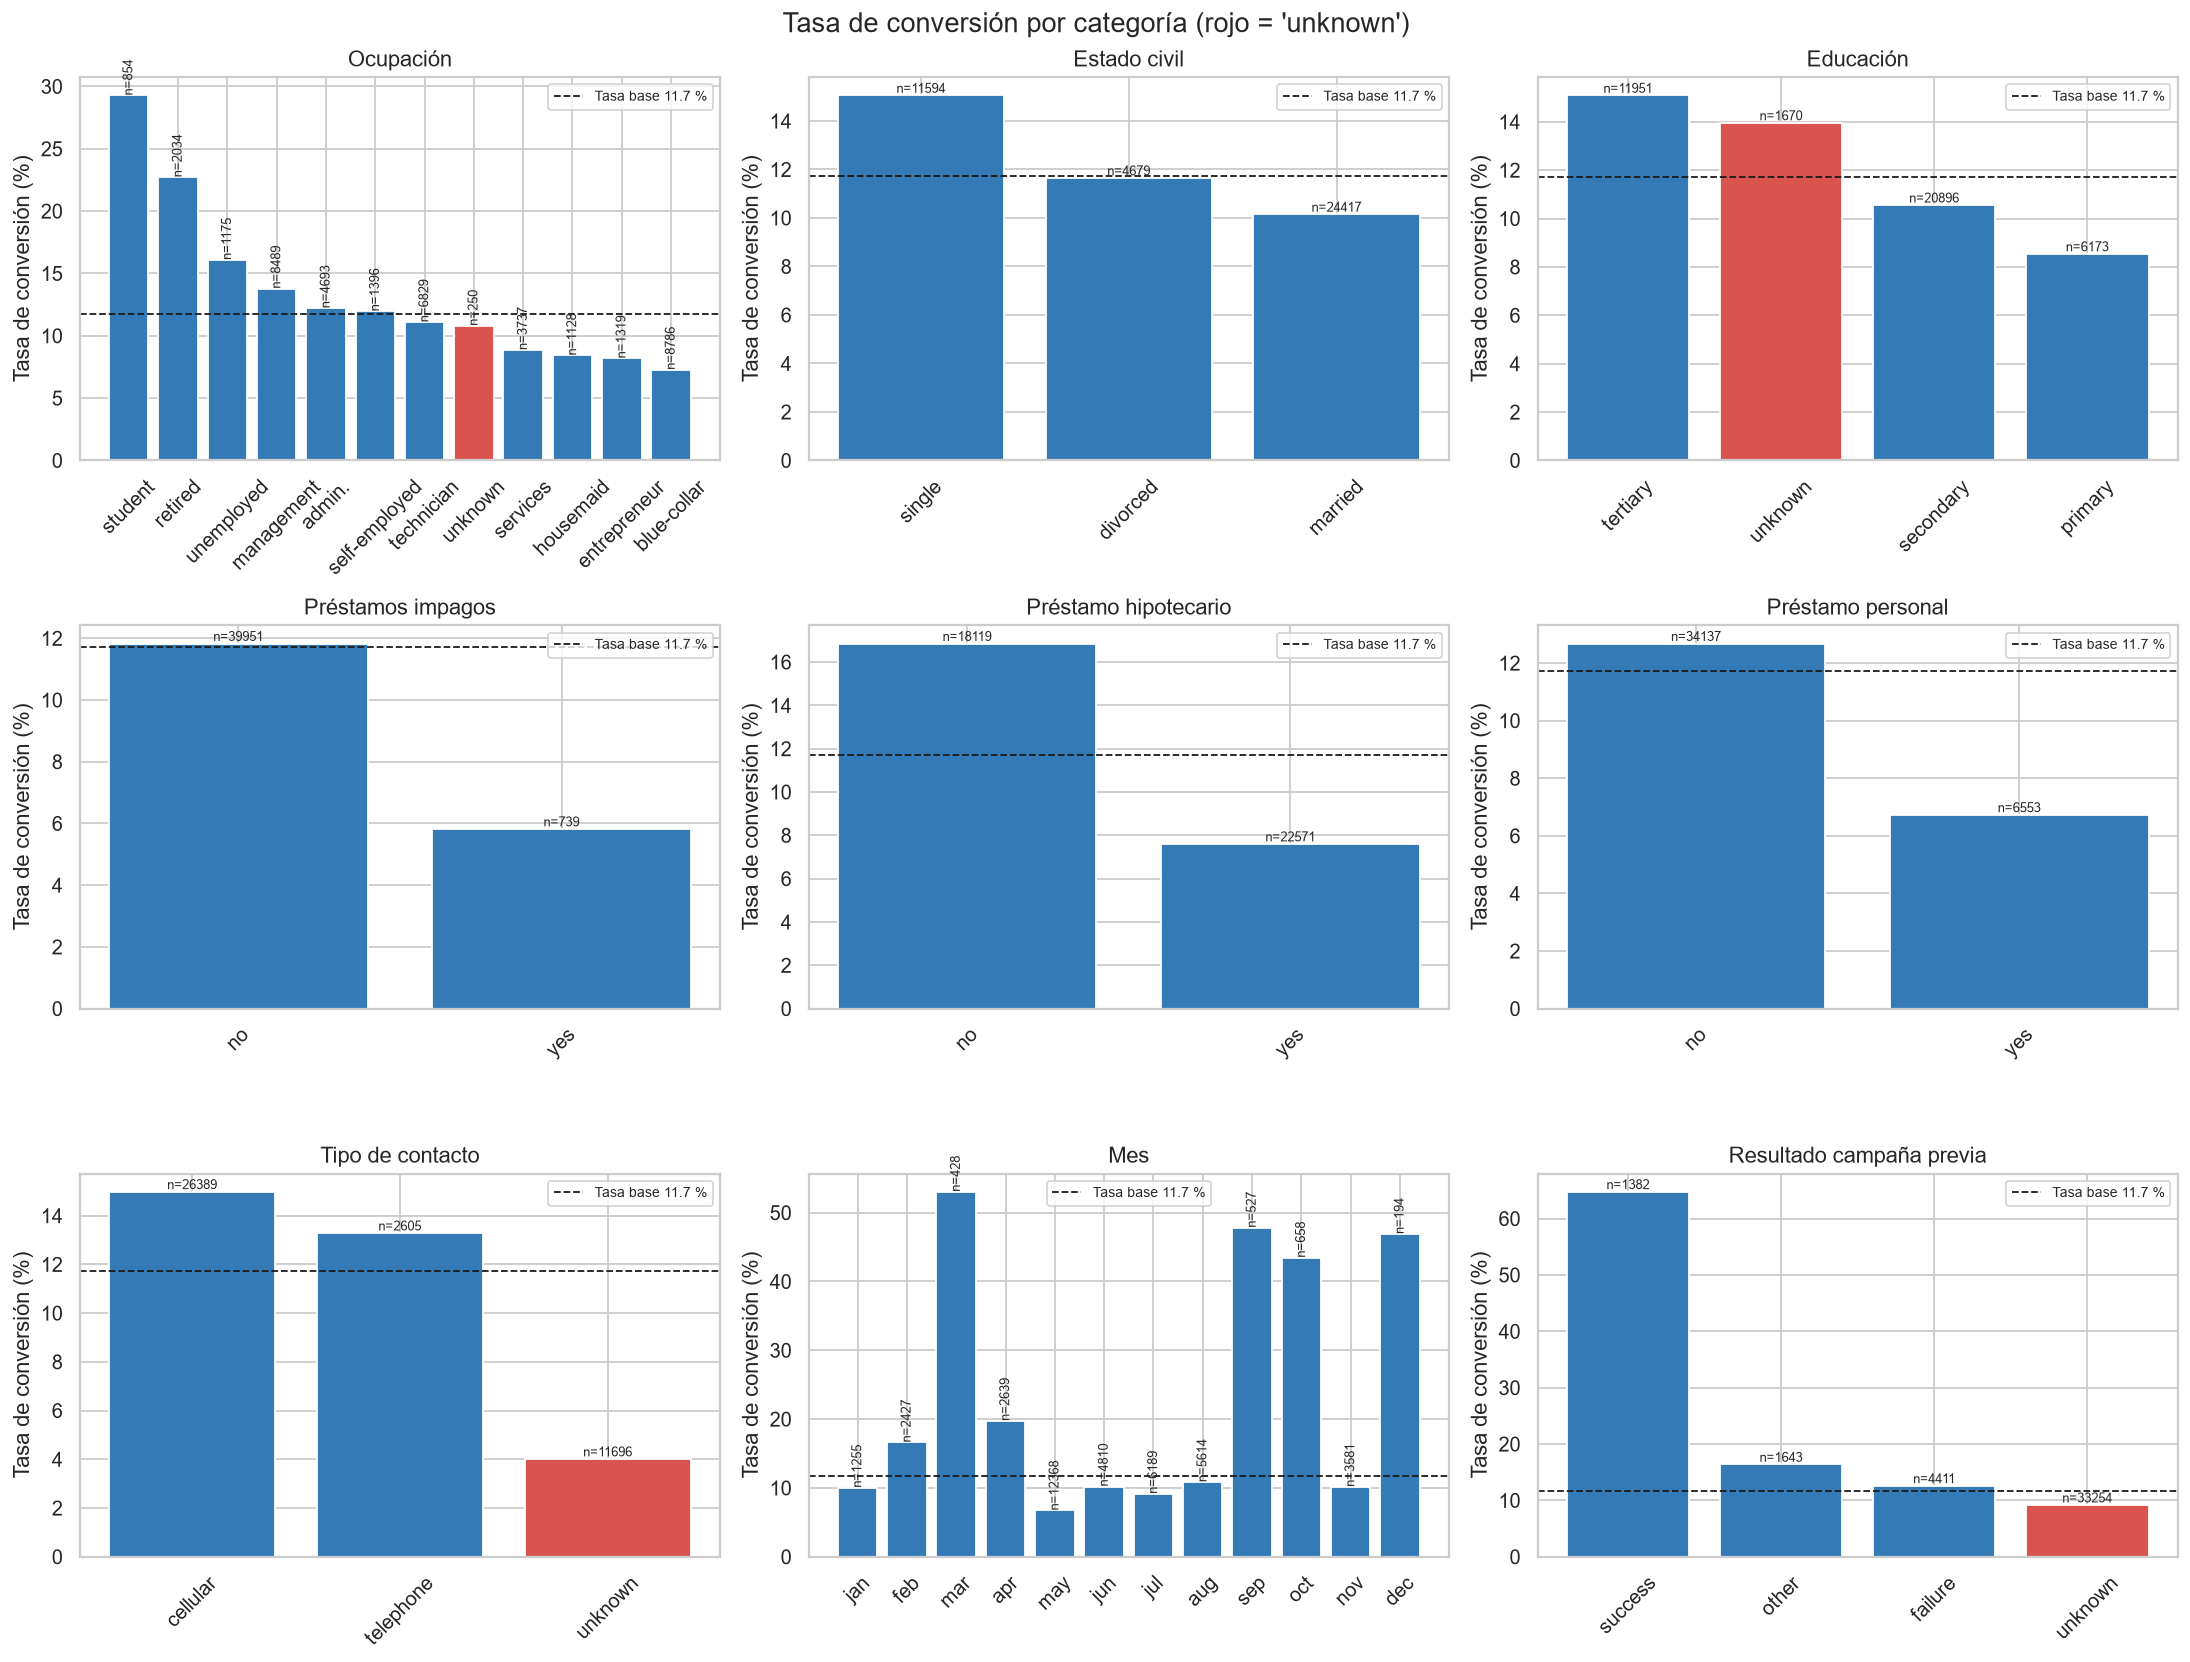

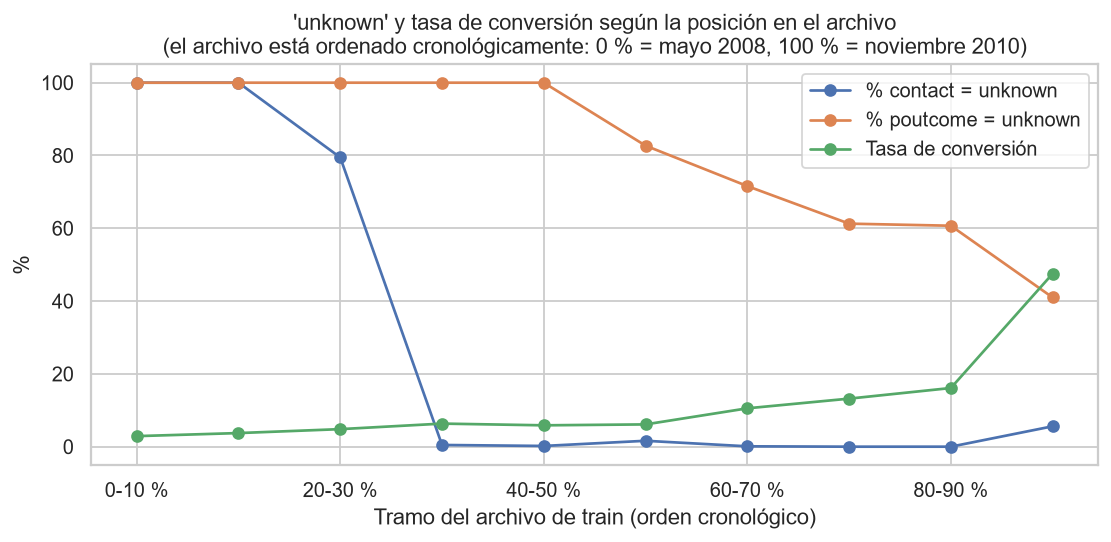

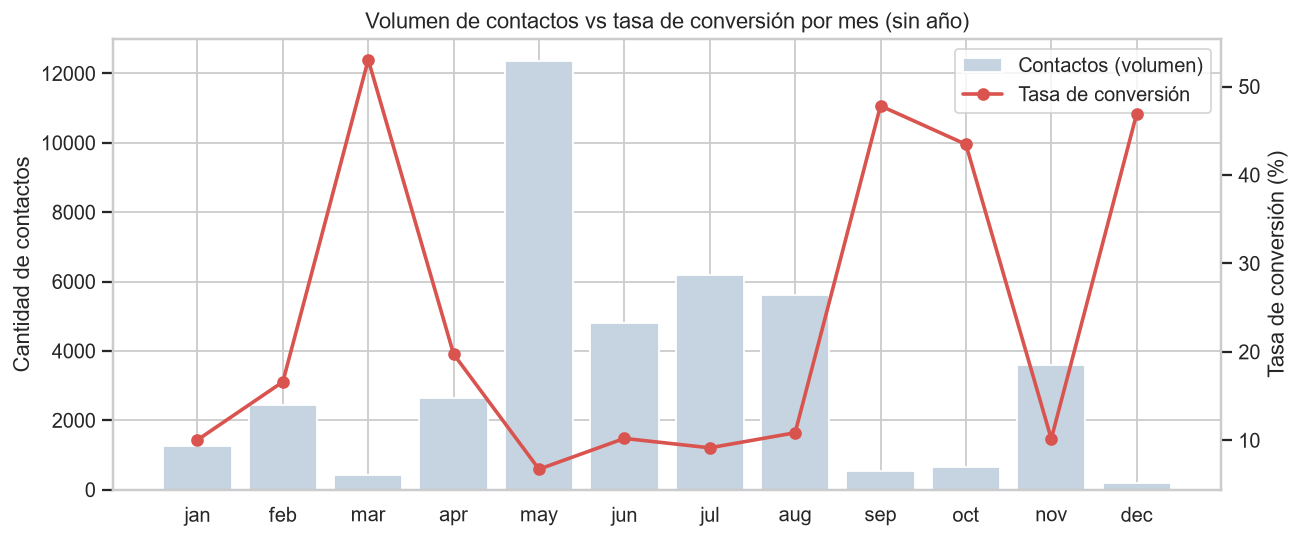

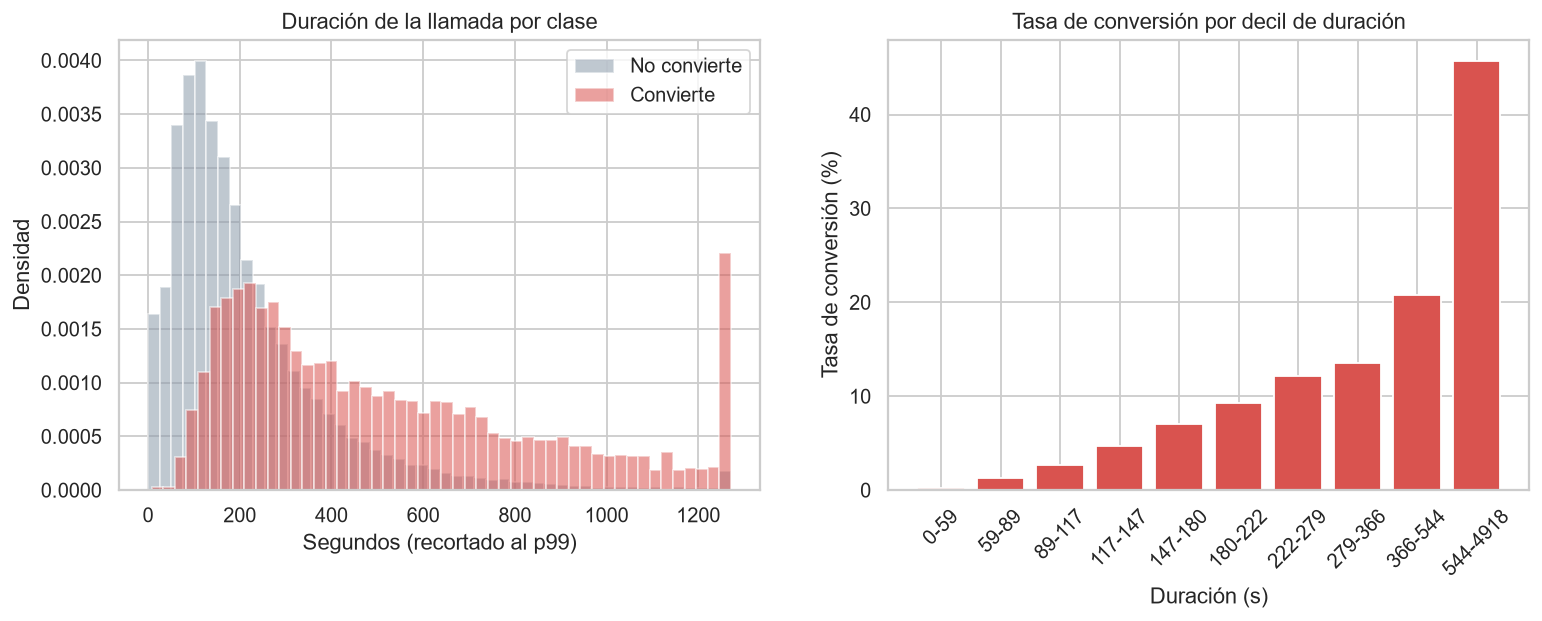

In [4]:
from bank_captacion.eda import run_eda
claves = run_eda()
for f in ["eda_conversion_by_category.png", "eda_unknown_by_file_position.png", "eda_month_volume_rate.png", "eda_duration_leakage.png"]:
    display(Image(filename=str(cfg.FIGURES_DIR / f), width=950))

**Lectura:**

- `unknown` no es un faltante al azar: por ejemplo, `contact = unknown` corresponde a un período sin
  registro del canal. Por eso se mantiene como categoría propia.
- El mes refleja el volumen de la operación del banco: a más llamadas, menor tasa de conversión.
- `duration` es **leakage**: solo se conoce después de llamar, así que se excluye del modelo.

## 5. Modelado

- **`MODO = "rapido"`** (por defecto): usa el modelo final ya entrenado del repositorio y muestra la
  comparación de algoritmos registrada.
- **`MODO = "completo"`**: reentrena todo desde cero (10 algoritmos, 3 estrategias de desbalance, Optuna).
  En el CPU de Colab puede tardar entre 20 y 40 minutos. Los resultados son los mismos porque la semilla
  está fija; solo cambian los tiempos medidos.

,label,family,pr_auc_fmt,roc_auc_fmt,lift@20_fmt,brier_fmt
0,LightGBM,Ensamble (boosting),0.4567 ± 0.0204,0.8030 ± 0.0111,3.1169 ± 0.0840,0.1458 ± 0.0040
1,XGBoost,Ensamble (boosting),0.4541 ± 0.0211,0.7994 ± 0.0113,3.0729 ± 0.0751,0.1456 ± 0.0034
2,Random Forest,Ensamble (bagging),0.4460 ± 0.0233,0.7975 ± 0.0097,3.1012 ± 0.0422,0.1135 ± 0.0030
3,Red neuronal (MLP 64-32),Redes neuronales,0.4304 ± 0.0199,0.7892 ± 0.0120,3.0131 ± 0.0750,0.0833 ± 0.0017
4,Regresión logística,Lineal,0.4117 ± 0.0117,0.7756 ± 0.0080,2.8527 ± 0.0895,0.1800 ± 0.0023
5,K vecinos más cercanos (k=51),Basado en instancias,0.4005 ± 0.0196,0.7709 ± 0.0074,2.8286 ± 0.0556,0.0853 ± 0.0016
6,Naive Bayes categórico,Probabilístico,0.3953 ± 0.0191,0.7611 ± 0.0071,2.7437 ± 0.1051,0.1144 ± 0.0033
7,SVM RBF (submuestra 10k),Márgenes / kernels,0.3621 ± 0.0197,0.7742 ± 0.0068,2.9837 ± 0.0903,NaN
8,Árbol de decisión (prof. 6),Árboles,0.3510 ± 0.0196,0.7544 ± 0.0108,2.7604 ± 0.1133,0.1842 ± 0.0033
9,Dummy (prior),Referencia,0.1172 ± 0.0001,0.5000 ± 0.0000,0.2799 ± 0.0315,0.1034 ± 0.0001


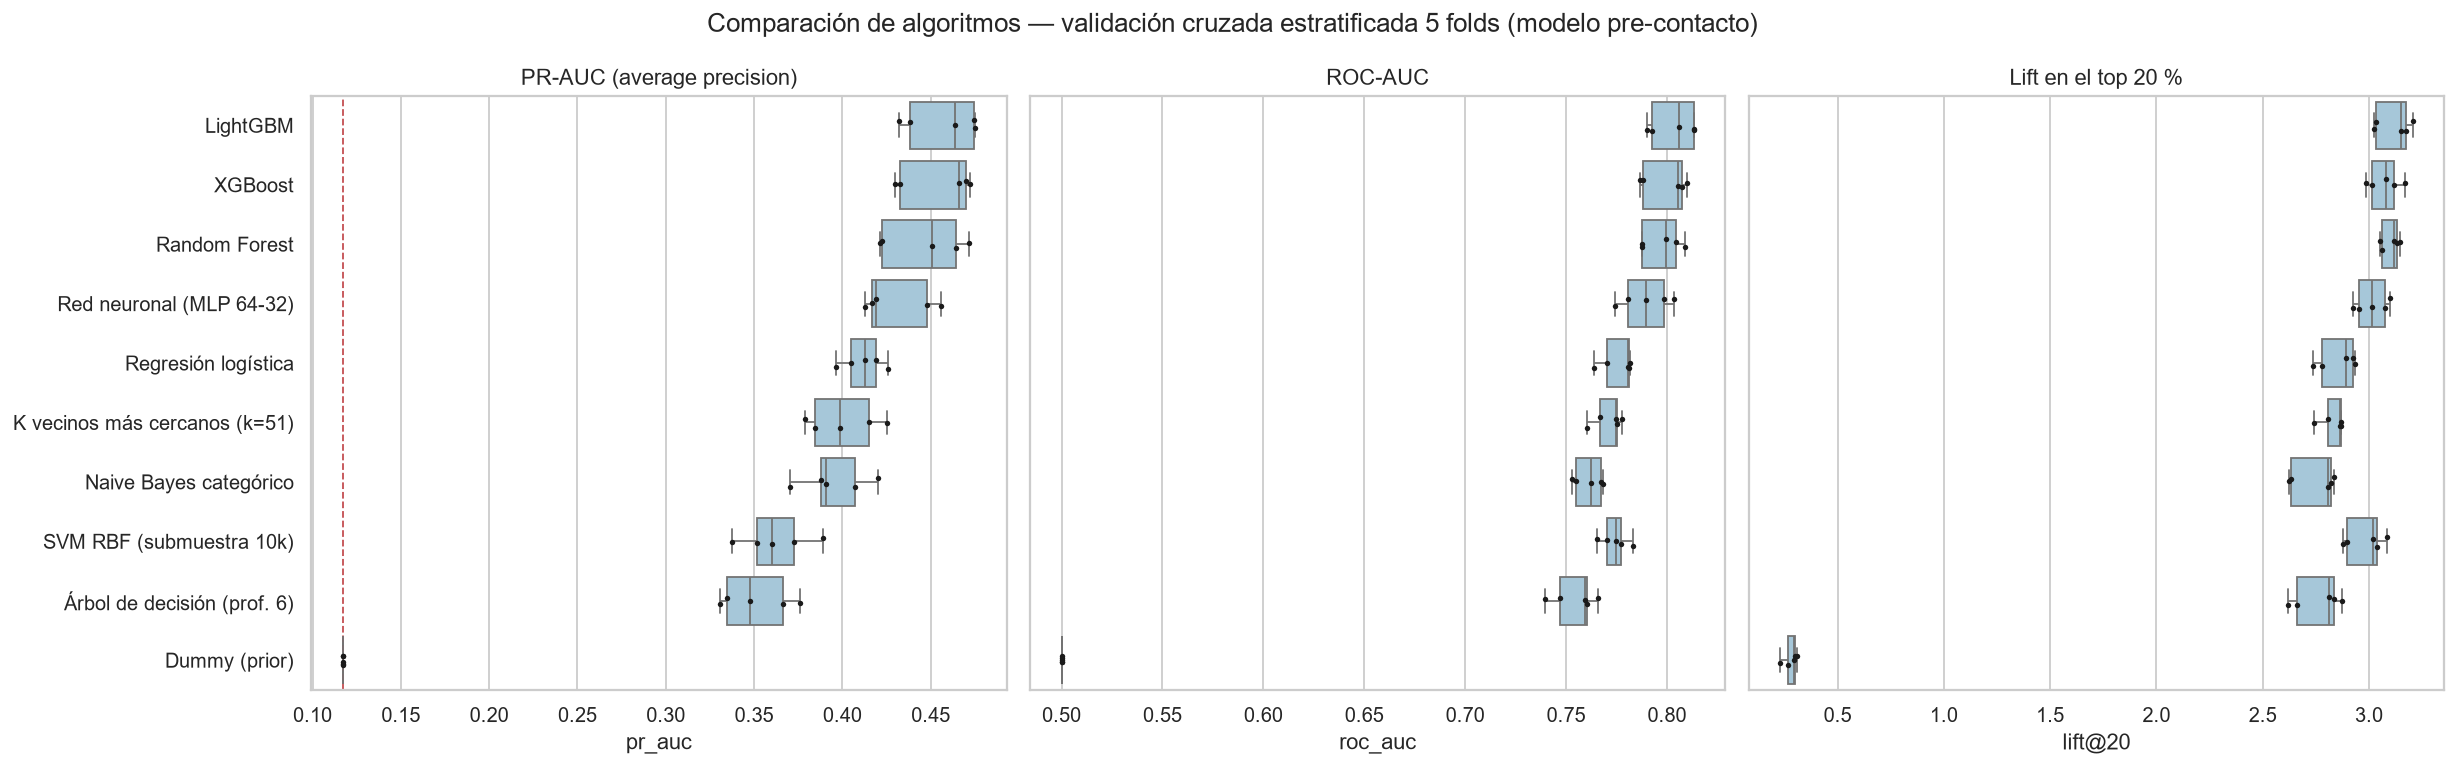

,candidate,pr_auc,pr_auc_std,lift@20,weighted_score
0,lightgbm_tuned,0.4660,0.0201,3.1525,0.6899
1,xgboost_tuned,0.4629,0.0246,3.1221,0.6669
2,xgboost_default,0.4522,0.0185,3.0917,0.6518
3,lightgbm_default,0.4589,0.0202,3.1221,0.6321
4,logreg_default,0.4117,0.0117,2.8527,0.4000


{
  "profit_threshold": 0.05,
  "profit_at_threshold": 59772.0,
  "contacted_pct_at_threshold": 61.90218726959941,
  "precision_at_threshold": 0.1686517389232968,
  "recall_at_threshold": 0.8909395973154363,
  "f1_at_threshold": 0.28361597008946454,
  "f1_threshold": 0.215,
  "f1_max": 0.4977951984321411,
  "profit_at_f1_threshold": 45363.0,
  "contacted_pct_at_f1_threshold": 13.362005406733841,
  "theoretical_threshold": 0.05,
  "profit_contact_all": 54670.0
}


In [5]:
MODO = "rapido"   # cambiar a "completo" para reentrenar desde cero

if MODO == "completo":
    from bank_captacion.train import run_training
    run_training()

cv = pd.read_csv(cfg.TABLES_DIR / "cv_results.csv")
display(cv[["label", "family", "pr_auc_fmt", "roc_auc_fmt", "lift@20_fmt", "brier_fmt"]])
display(Image(filename=str(cfg.FIGURES_DIR / "model_cv_comparison.png"), width=1000))
display(pd.read_csv(cfg.TABLES_DIR / "decision_matrix.csv")[["candidate", "pr_auc", "pr_auc_std", "lift@20", "weighted_score"]])
print(json.dumps(json.loads((cfg.TABLES_DIR / "threshold_choice.json").read_text()), indent=2))

## 5 bis. Los 10 modelos en vivo

Cada modelo se entrena y evalúa **ahora**, con la misma validación cruzada (5 particiones de los 40.690
clientes). Para cada uno se muestra:

- **Familia**, **cómo funciona** y **por qué se incluyó** en la comparación.
- El **diagrama de su pipeline**: preparación de datos → modelo. Se puede hacer clic para desplegar los detalles.
- Su resultado: **PR-AUC** (qué tan bien encuentra a los que convierten) y **ROC-AUC**.

Para probar un solo modelo a pedido: `probar_modelo("knn")`. Los nombres posibles son `lightgbm`, `xgboost`,
`random_forest`, `mlp`, `logreg`, `knn`, `naive_bayes`, `svm_rbf`, `tree` y `dummy`.

In [6]:
import time, warnings
from IPython.display import HTML
from sklearn import set_config
from bank_captacion.data import load_clean, split_xy
from bank_captacion.models import MODEL_SPECS, make_model
from bank_captacion.train import cv_evaluate, get_folds

warnings.filterwarnings("ignore")
set_config(display="diagram")
_train, _ = load_clean()
X_tr, y_tr = split_xy(_train)
FOLDS = get_folds(X_tr, y_tr)

POR_QUE = {
    "lightgbm": "Representa el boosting, el estado del arte en datos de tablas. Admite categorías nativas.",
    "xgboost": "Segunda implementación de boosting, para confirmar que el resultado no depende de una librería.",
    "random_forest": "Representa los ensambles por votación (bagging): robusto y difícil de sobreajustar.",
    "mlp": "Representa a las redes neuronales vistas en la materia.",
    "logreg": "Es el baseline clásico, simple e interpretable: todo modelo complejo debe superarlo.",
    "knn": "Representa los métodos basados en similitud entre casos.",
    "naive_bayes": "Representa los modelos probabilísticos: simple, rápido y buena referencia.",
    "svm_rbf": "Representa los métodos de márgenes con kernels (fronteras no lineales).",
    "tree": "Genera reglas que se le pueden explicar al negocio.",
    "dummy": "Sirve como piso: muestra cuánto aporta realmente cada modelo.",
}
RESULTADOS = {}

def probar_modelo(nombre):
    spec = MODEL_SPECS[nombre]
    display(HTML(f"<h3 style='margin-bottom:4px'>{spec.label}</h3>"
                 f"<p style='margin-top:0'><b>Familia:</b> {spec.family}<br><b>Cómo funciona:</b> {spec.rationale}"
                 f"<br><b>Por qué lo incluí:</b> {POR_QUE[nombre]}</p>"))
    display(make_model(nombre))                       # diagrama del pipeline: preparación → modelo
    t0 = time.time()
    folds_df, _ = cv_evaluate(nombre, X_tr, y_tr, FOLDS, imbalance="weights")
    r = {"Modelo": spec.label, "Familia": spec.family,
         "PR-AUC": round(folds_df.pr_auc.mean(), 3), "± variación": round(folds_df.pr_auc.std(), 3),
         "ROC-AUC": round(folds_df.roc_auc.mean(), 3), "Segundos": round(time.time() - t0, 1)}
    RESULTADOS[nombre] = r
    display(HTML(f"<p style='font-size:15px'>➜ <b>PR-AUC = {r['PR-AUC']:.3f}</b> ± {r['± variación']:.3f} · "
                 f"ROC-AUC = {r['ROC-AUC']:.3f} · {r['Segundos']} s</p><hr>"))
    return r

print("Listo. Usar probar_modelo('nombre') o ejecutar la celda siguiente para los 10.")

Listo. Usar probar_modelo('nombre') o ejecutar la celda siguiente para los 10.


In [7]:
# Los 10 modelos, uno por uno (en Colab tarda unos minutos; el SVM es el más lento)
for nombre in ["dummy", "logreg", "tree", "knn", "naive_bayes", "random_forest", "lightgbm", "xgboost", "mlp", "svm_rbf"]:
    probar_modelo(nombre)

tabla = pd.DataFrame(RESULTADOS.values()).sort_values("PR-AUC", ascending=False).reset_index(drop=True)
tabla.index = tabla.index + 1
display(HTML("<h3>Ranking final (mismo resultado que la slide de comparación)</h3>"))
display(tabla)

,steps,"[('features', ...), ('prep', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,use_duration,False
,cap_quantile,0.99
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. ``""{feature_name}__{transformer_name}""``. See :meth:`str.format` method from the standard library for more info... versionadded:: 1.0.. versionchanged:: 1.6 `verbose_feature_names_out` can be a callable or a string to be formatted.",False
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for

,steps,"[('features', ...), ('prep', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,use_duration,False
,cap_quantile,0.99
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. ``""{feature_name}__{transformer_name}""``. See :meth:`str.format` method from the standard library for more info... versionadded:: 1.0.. versionchanged:: 1.6 `verbose_feature_names_out` can be a callable or a string to be formatted.",False
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for

,steps,"[('features', ...), ('prep', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,use_duration,False
,cap_quantile,0.99
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. ``""{feature_name}__{transformer_name}""``. See :meth:`str.format` method from the standard library for more info... versionadded:: 1.0.. versionchanged:: 1.6 `verbose_feature_names_out` can be a callable or a string to be formatted.",False
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for

,steps,"[('features', ...), ('prep', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,use_duration,False
,cap_quantile,0.99
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. ``""{feature_name}__{transformer_name}""``. See :meth:`str.format` method from the standard library for more info... versionadded:: 1.0.. versionchanged:: 1.6 `verbose_feature_names_out` can be a callable or a string to be formatted.",False
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for

,steps,"[('features', ...), ('prep', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,use_duration,False
,cap_quantile,0.99
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cont', ...), ('disc', ...), ...]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. ``""{feature_name}__{transformer_name}""``. See :meth:`str.format` method from the standard library for more info... versionadded:: 1.0.. versionchanged:: 1.6 `verbose_feature_names_out` can be a callable or a string to be formatted.",False
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jo

,steps,"[('features', ...), ('prep', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,use_duration,False
,cap_quantile,0.99
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. ``""{feature_name}__{transformer_name}""``. See :meth:`str.format` method from the standard library for more info... versionadded:: 1.0.. versionchanged:: 1.6 `verbose_feature_names_out` can be a callable or a string to be formatted.",False
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for

,steps,"[('features', ...), ('prep', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,use_duration,False
,cap_quantile,0.99
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. ``""{feature_name}__{transformer_name}""``. See :meth:`str.format` method from the standard library for more info... versionadded:: 1.0.. versionchanged:: 1.6 `verbose_feature_names_out` can be a callable or a string to be formatted.",False
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for

,steps,"[('features', ...), ('prep', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,use_duration,False
,cap_quantile,0.99
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. ``""{feature_name}__{transformer_name}""``. See :meth:`str.format` method from the standard library for more info... versionadded:: 1.0.. versionchanged:: 1.6 `verbose_feature_names_out` can be a callable or a string to be formatted.",False
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for

,steps,"[('features', ...), ('prep', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,use_duration,False
,cap_quantile,0.99
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. ``""{feature_name}__{transformer_name}""``. See :meth:`str.format` method from the standard library for more info... versionadded:: 1.0.. versionchanged:: 1.6 `verbose_feature_names_out` can be a callable or a string to be formatted.",False
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for

,steps,"[('features', ...), ('prep', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,use_duration,False
,cap_quantile,0.99
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. ``""{feature_name}__{transformer_name}""``. See :meth:`str.format` method from the standard library for more info... versionadded:: 1.0.. versionchanged:: 1.6 `verbose_feature_names_out` can be a callable or a string to be formatted.",False
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for

,Modelo,Familia,PR-AUC,± variación,ROC-AUC,Segundos
1,LightGBM,Ensamble (boosting),0.457,0.020,0.803,1.2
2,XGBoost,Ensamble (boosting),0.454,0.021,0.799,1.9
3,Random Forest,Ensamble (bagging),0.446,0.023,0.797,3.2
4,Red neuronal (MLP 64-32),Redes neuronales,0.430,0.020,0.789,1.9
5,Regresión logística,Lineal,0.412,0.012,0.776,0.5
6,K vecinos más cercanos (k=51),Basado en instancias,0.400,0.020,0.771,0.8
7,Naive Bayes categórico,Probabilístico,0.395,0.019,0.761,0.3
8,SVM RBF (submuestra 10k),Márgenes / kernels,0.362,0.020,0.774,6.4
9,Árbol de decisión (prof. 6),Árboles,0.351,0.020,0.754,0.3
10,Dummy (prior),Referencia,0.117,0.000,0.500,1.9


## 6. Evaluación única sobre el hold-out (4.521 clientes)

El modelo, sus hiperparámetros y el umbral se fijaron antes de mirar el test.

,label,roc_auc,pr_auc,lift@10,lift@20,gain@20,brier
0,"LightGBM (final, pre-contacto)",0.7836,0.4354,4.2143,2.9820,0.5969,0.0822
1,Regresión logística (baseline),0.7379,0.3494,3.8120,2.4546,0.4914,0.1834
2,Dummy (prior),0.5000,0.1152,1.0919,0.9876,0.1977,0.1020
3,LightGBM + duration (leakage),0.9326,0.6072,5.4785,4.1614,0.8330,0.0622


,strategy,contacted,contacted_pct,conversions,gain_pct,precision_pct,lift,profit,profit_vs_all
0,Top 10 % del ranking,453,10.00,220,42.23,48.57,4.21,3947.0,-1952.0
1,Top 20 % del ranking,905,20.00,311,59.69,34.36,2.98,5315.0,-584.0
2,Top 30 % del ranking,1357,30.00,353,67.75,26.01,2.26,5703.0,-196.0
3,Umbral operativo (0.050),2762,61.09,451,86.56,16.33,1.42,6258.0,359.0
4,Contactar a todos,4521,100.00,521,100.00,11.52,1.00,5899.0,0.0
5,No contactar a nadie,0,0.00,0,0.00,NaN,NaN,0.0,-5899.0


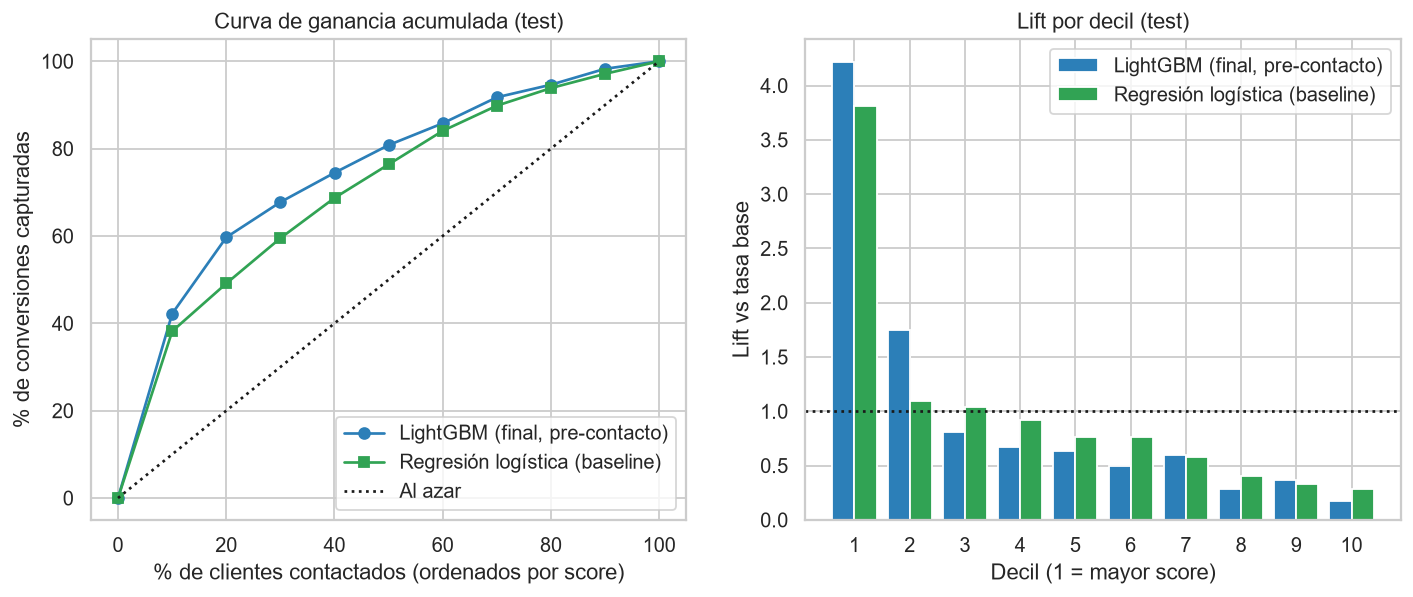

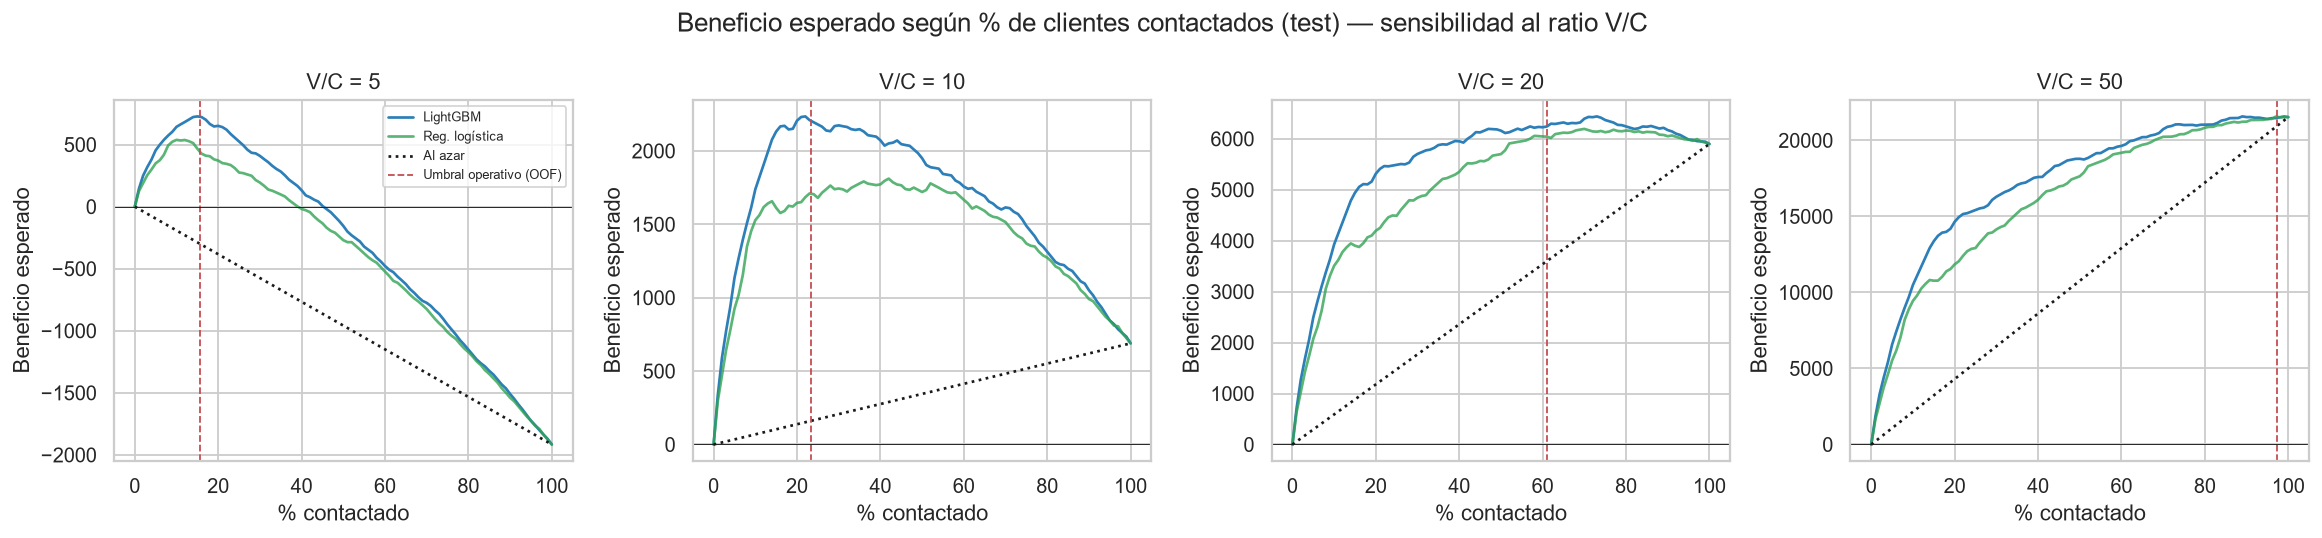

,check,value,reference,ok
0,"ROC-AUC sin duration vs referencia 0,75–0,80",0.7836,"0,75–0,80 (rango de referencia del enunciado p...",True
1,ROC-AUC con duration (leakage) en rango típico...,0.9326,"> 0,90 esperado: duration por sí sola tiene RO...",True
2,PR-AUC muy por encima del azar (prevalencia),0.4354,piso = prevalencia en test (0.115),True
3,Modelo final supera a la regresión logística,0.4354,PR-AUC logística = 0.3494,True
4,PR-AUC en test dentro de ±2 desvíos de la CV,0.4354,CV = 0.4660 ± 0.0201,True


In [8]:
from bank_captacion.evaluate import run_evaluation
run_evaluation()
display(pd.read_csv(cfg.TABLES_DIR / "test_metrics.csv")[["label", "roc_auc", "pr_auc", "lift@10", "lift@20", "gain@20", "brier"]])
display(pd.read_csv(cfg.TABLES_DIR / "test_business_summary.csv"))
for f in ["test_gain_lift.png", "test_profit_curves.png"]:
    display(Image(filename=str(cfg.FIGURES_DIR / f), width=1000))
display(pd.read_csv(cfg.TABLES_DIR / "reasonableness.csv"))

## 7. Explicabilidad (SHAP, regresión logística y árbol de reglas)

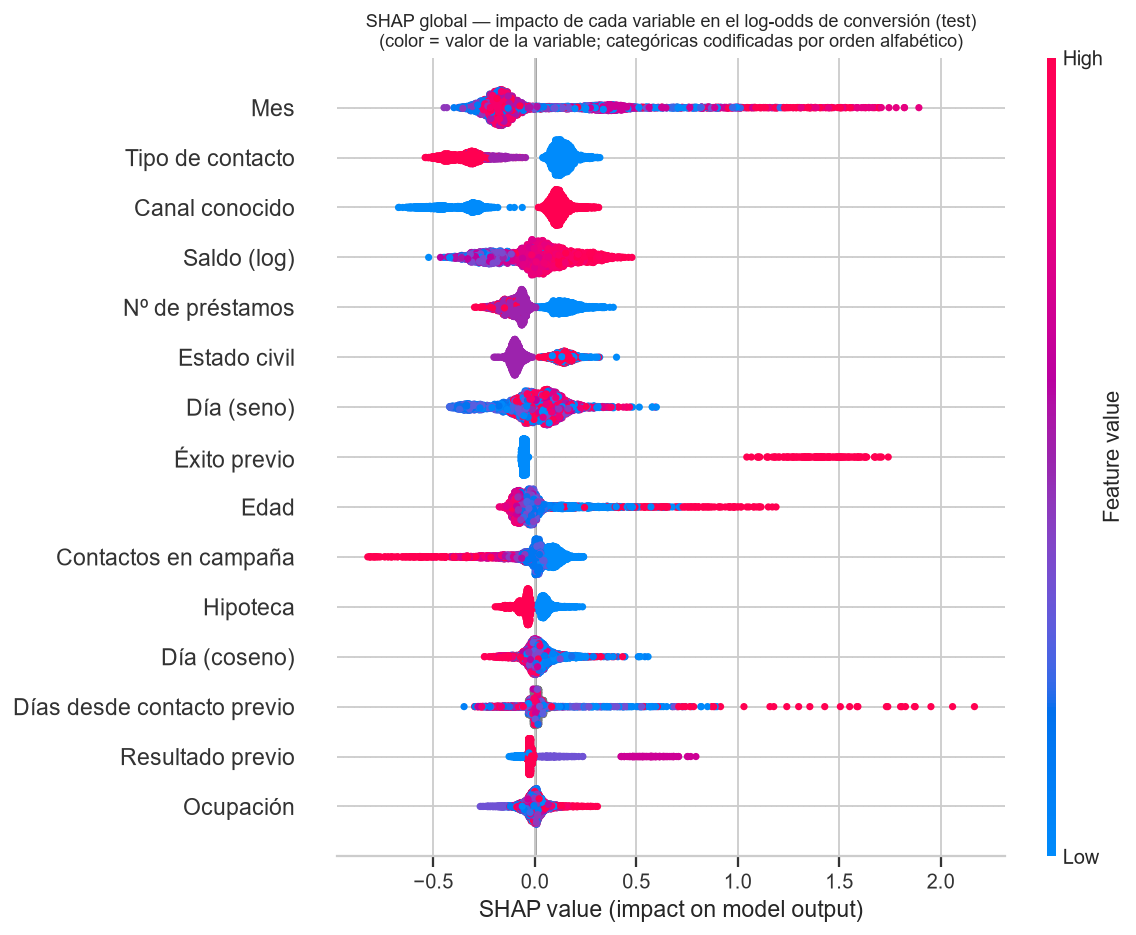

,rule,n_train,share_pct,conversion_rate,lift
0,poutcome = success Y housing = no Y pdays_clea...,426,1.0469,0.7512,6.4105
1,poutcome = success Y housing = no Y pdays_clea...,525,1.2902,0.6590,5.6243
2,poutcome = success Y housing = yes Y day_cos >...,218,0.5358,0.6055,5.1674
3,poutcome = success Y housing = yes Y day_cos <...,213,0.5235,0.4554,3.8864
4,poutcome != success Y n_credit_products <= 0.5...,6048,14.8636,0.2199,1.8767
5,poutcome != success Y n_credit_products <= 0.5...,8369,20.5677,0.1037,0.8851
6,poutcome != success Y n_credit_products > 0.50...,14759,36.2718,0.0848,0.7239
7,poutcome != success Y n_credit_products > 0.50...,10132,24.9005,0.0417,0.3563


In [9]:
from bank_captacion.explain import run_explain
run_explain()
display(Image(filename=str(cfg.FIGURES_DIR / "shap_summary.png"), width=800))
display(pd.read_csv(cfg.TABLES_DIR / "rules_tree_leaves.csv"))

## 8. Usar el modelo

Primero localmente, con el pipeline guardado: recibe datos crudos y devuelve la probabilidad y las variables
que más pesaron. Después, contra la **API publicada en la web**.

In [10]:
from bank_captacion.inference import load_model, score_frame, top_contributions

modelo, meta = load_model()
cliente = pd.DataFrame([{"age": 64, "job": "retired", "marital": "married", "education": "primary", "default": "no",
                         "balance": 43, "housing": "no", "loan": "no", "contact": "cellular", "day": 10, "month": "mar",
                         "campaign": 1, "pdays": 90, "previous": 2, "poutcome": "success"}])
p = modelo.predict_proba(cliente)[0, 1]
print(f"Probabilidad de conversión: {p:.1%} → {'LLAMAR' if p >= meta['threshold'] else 'no llamar'} (umbral {meta['threshold']:.0%})")
for f in top_contributions(modelo, cliente)[0]:
    print(f"  {f['label']:22s} = {str(f['value']):10s} {f['effect']} la probabilidad ({f['shap']:+.2f})")

Probabilidad de conversión: 82.4% → LLAMAR (umbral 5%)
  Éxito previo           = 1          aumenta la probabilidad (+1.20)
  Mes                    = mar        aumenta la probabilidad (+0.81)
  Resultado previo       = success    aumenta la probabilidad (+0.51)


In [11]:
import requests
API = "https://captacion-clientes.onrender.com"
try:
    r = requests.post(f"{API}/predict", json=cliente.iloc[0].to_dict(), timeout=120)  # la primera vez puede tardar ~1 min (se despierta)
    print("Respuesta de la API publicada:", json.dumps(r.json(), indent=2, ensure_ascii=False)[:600])
except Exception as e:
    print("La API no respondió a tiempo (plan gratuito dormido). Abrir", API, "y reintentar.", e)

Respuesta de la API publicada: {
  "probability": 0.82406,
  "contact_recommended": true,
  "recommendation": "llamar",
  "threshold": 0.05,
  "decile": 1,
  "top_factors": [
    {
      "feature": "prev_campaign_success",
      "label": "Éxito previo",
      "value": 1,
      "shap": 1.2046,
      "effect": "aumenta"
    },
    {
      "feature": "month",
      "label": "Mes",
      "value": "mar",
      "shap": 0.8126,
      "effect": "aumenta"
    },
    {
      "feature": "poutcome",
      "label": "Resultado previo",
      "value": "success",
      "shap": 0.5082,
      "effect": "aumenta"
    }
  ],
  "explanation": "


## Material complementario

- **Informe completo:** [`reports/informe_final.pdf`](https://github.com/fcaceres-create/caece-aprendizaje-artificial-tpfinal/blob/main/reports/informe_final.pdf)
- **Registro de decisiones:** [`docs/decision_log.md`](https://github.com/fcaceres-create/caece-aprendizaje-artificial-tpfinal/blob/main/docs/decision_log.md)
- **Preparación de los datos, paso a paso:** [`docs/03_preparacion_datos.md`](https://github.com/fcaceres-create/caece-aprendizaje-artificial-tpfinal/blob/main/docs/03_preparacion_datos.md)
- **Notebooks detallados:** `notebooks/01_eda.ipynb`, `02_modelado.ipynb`, `03_evaluacion_y_negocio.ipynb`